# Vehicle Fuel Consumption Analysis and Visualization
**Course:** EDAV (22ADC32N) – Course-End Project  
**Department:** Information Technology, CBIT  
**Semester:** III Semester, 2026–27

## Objective
Analyze vehicle fuel consumption using NumPy, Pandas, and visualization tools. Explore how vehicle type, engine size, distance travelled, speed, and driving conditions relate to fuel efficiency.

>

## Environment Setup
This notebook uses `numpy`, `pandas`, and `matplotlib`. Run the following cell if any library is missing.

In [ ]:
# If needed, uncomment and run:
# %pip install numpy pandas matplotlib

## Dataset Preparation
The demonstration dataset contains vehicle category, engine size, distance travelled, fuel consumed, average speed, and driving condition. The values are simulated for demonstration and should not be presented as real-world measurements.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fixed seed makes the demonstration results reproducible.
rng = np.random.default_rng(42)
n = 240

vehicle_types = rng.choice(
    ["Hatchback", "Sedan", "SUV", "Van"],
    size=n,
    p=[0.30, 0.30, 0.28, 0.12]
)
engine_l = np.select(
    [vehicle_types == "Hatchback", vehicle_types == "Sedan",
     vehicle_types == "SUV", vehicle_types == "Van"],
    [1.2, 1.6, 2.2, 2.0]
).astype(float)
engine_l += rng.normal(0, 0.18, n)
engine_l = np.clip(engine_l, 0.8, 3.5)

distance_km = rng.uniform(20, 500, n)
avg_speed_kmh = rng.uniform(15, 100, n)
driving_condition = rng.choice(["City", "Highway", "Mixed"], size=n, p=[0.40, 0.35, 0.25])

# Simulated fuel economy in km/L; larger engines and city driving tend to use more fuel.
condition_penalty = np.select(
    [driving_condition == "City", driving_condition == "Highway",
     driving_condition == "Mixed"],
    [2.2, -0.5, 0.8]
)
efficiency_kmpl = 18.5 - (engine_l * 2.0) - condition_penalty + (avg_speed_kmh * 0.012)
efficiency_kmpl += rng.normal(0, 1.4, n)
efficiency_kmpl = np.clip(efficiency_kmpl, 4.5, 30)
fuel_litres = distance_km / efficiency_kmpl

df = pd.DataFrame({
    "Vehicle_Type": vehicle_types,
    "Engine_Size_L": engine_l.round(2),
    "Distance_km": distance_km.round(1),
    "Fuel_Consumed_L": fuel_litres.round(2),
    "Average_Speed_kmh": avg_speed_kmh.round(1),
    "Driving_Condition": driving_condition,
    "Fuel_Efficiency_km_per_L": efficiency_kmpl.round(2)
})

# Add a few missing values to demonstrate data cleaning.
for col in ["Engine_Size_L", "Average_Speed_kmh"]:
    missing_rows = rng.choice(df.index, size=5, replace=False)
    df.loc[missing_rows, col] = np.nan

df.head()

,Vehicle_Type,Engine_Size_L,Distance_km,Fuel_Consumed_L,Average_Speed_kmh,Driving_Condition,Fuel_Efficiency_km_per_L
0,SUV,2.07,171.8,11.98,47.7,Mixed,14.34
1,Sedan,1.48,398.0,28.24,20.1,City,14.09
2,SUV,1.81,283.6,16.83,74.3,Highway,16.85
3,SUV,2.17,227.1,17.20,32.6,Highway,13.20
4,Hatchback,1.01,320.5,17.17,40.7,Highway,18.67


## Initial Inspection and Data Cleaning
**Concept:** Inspect rows, column types, missing values, duplicates, and unusual values before analysis. Missing numeric values are filled with the median; duplicate rows are removed.

In [ ]:
print("Dataset shape:", df.shape)
display(df.head())
print("\\nData types:")
print(df.dtypes)
print("\\nMissing values per column:")
print(df.isna().sum())
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nNumerical summary:")
display(df.describe().round(2))

Dataset shape: (240, 7)


,Vehicle_Type,Engine_Size_L,Distance_km,Fuel_Consumed_L,Average_Speed_kmh,Driving_Condition,Fuel_Efficiency_km_per_L
0,SUV,2.07,171.8,11.98,47.7,Mixed,14.34
1,Sedan,1.48,398.0,28.24,20.1,City,14.09
2,SUV,1.81,283.6,16.83,74.3,Highway,16.85
3,SUV,2.17,227.1,17.20,32.6,Highway,13.20
4,Hatchback,1.01,320.5,17.17,40.7,Highway,18.67


\nData types:
Vehicle_Type                 object
Engine_Size_L               float64
Distance_km                 float64
Fuel_Consumed_L             float64
Average_Speed_kmh           float64
Driving_Condition            object
Fuel_Efficiency_km_per_L    float64
dtype: object
\nMissing values per column:
Vehicle_Type                0
Engine_Size_L               5
Distance_km                 0
Fuel_Consumed_L             0
Average_Speed_kmh           5
Driving_Condition           0
Fuel_Efficiency_km_per_L    0
dtype: int64
\nDuplicate rows: 0
\nNumerical summary:


,Engine_Size_L,Distance_km,Fuel_Consumed_L,Average_Speed_kmh,Fuel_Efficiency_km_per_L
count,235.00,240.00,240.00,235.00,240.00
mean,1.69,265.76,18.21,55.47,14.96
std,0.45,140.36,10.24,25.31,2.18
min,0.80,22.20,1.55,15.10,8.16
25%,1.31,156.45,10.51,32.65,13.60
50%,1.66,266.10,17.92,54.70,14.97
75%,2.09,390.80,25.82,78.00,16.61
max,2.58,499.40,59.94,99.40,19.96


In [ ]:
# Keep an untouched copy if you want to compare before and after cleaning.
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()

numeric_cols = df_clean.select_dtypes(include="number").columns
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Missing values after cleaning:")
print(df_clean.isna().sum())
print("Rows after removing duplicates:", len(df_clean))

Missing values after cleaning:
Vehicle_Type                0
Engine_Size_L               0
Distance_km                 0
Fuel_Consumed_L             0
Average_Speed_kmh           0
Driving_Condition           0
Fuel_Efficiency_km_per_L    0
dtype: int64
Rows after removing duplicates: 240


## Q1. Use NumPy to Calculate Fuel Consumption Statistics [CO1,BL3]
**Concept:** NumPy array operations calculate the average, minimum, and maximum fuel consumed. This gives a quick overview of the range of fuel use in the dataset.

In [ ]:
fuel_array = df_clean["Fuel_Consumed_L"].to_numpy()

print(f"Average fuel consumed: {np.mean(fuel_array):.2f} L")
print(f"Minimum fuel consumed: {np.min(fuel_array):.2f} L")
print(f"Maximum fuel consumed: {np.max(fuel_array):.2f} L")

# Compare average fuel consumed by vehicle category using NumPy arrays.
print("\\nAverage fuel consumed by vehicle type:")
for vehicle in sorted(df_clean["Vehicle_Type"].unique()):
    values = df_clean.loc[df_clean["Vehicle_Type"] == vehicle, "Fuel_Consumed_L"].to_numpy()
    print(f"{vehicle}: {np.mean(values):.2f} L")

Average fuel consumed: 18.21 L
Minimum fuel consumed: 1.55 L
Maximum fuel consumed: 59.94 L
\nAverage fuel consumed by vehicle type:
Hatchback: 16.76 L
SUV: 18.97 L
Sedan: 18.81 L
Van: 18.71 L


**Conclusion:** The printed statistics describe fuel use across the simulated trips. Total fuel consumed depends strongly on distance travelled, so compare fuel efficiency (km/L) as well when evaluating vehicles fairly.

## Q2. Analyze Vehicle Type and Driving Condition with Pandas [CO2,BL4]
**Concept:** `groupby()` and aggregation compare average fuel efficiency and fuel consumption across vehicle categories and driving conditions.

In [ ]:
vehicle_summary = df_clean.groupby("Vehicle_Type").agg(
    Trips=("Vehicle_Type", "size"),
    Mean_Fuel_Consumed_L=("Fuel_Consumed_L", "mean"),
    Mean_Efficiency_km_per_L=("Fuel_Efficiency_km_per_L", "mean"),
    Mean_Distance_km=("Distance_km", "mean")
).round(2)

condition_summary = df_clean.groupby("Driving_Condition").agg(
    Trips=("Driving_Condition", "size"),
    Mean_Fuel_Consumed_L=("Fuel_Consumed_L", "mean"),
    Mean_Efficiency_km_per_L=("Fuel_Efficiency_km_per_L", "mean")
).round(2)

display(vehicle_summary)
display(condition_summary)

,Trips,Mean_Fuel_Consumed_L,Mean_Efficiency_km_per_L,Mean_Distance_km
Vehicle_Type,,,,
Hatchback,74,16.76,16.12,266.17
SUV,66,18.97,13.36,251.03
Sedan,73,18.81,15.23,279.29
Van,27,18.71,14.98,264.00


,Trips,Mean_Fuel_Consumed_L,Mean_Efficiency_km_per_L
Driving_Condition,,,
City,88,20.46,13.41
Highway,86,16.40,16.28
Mixed,66,17.58,15.31


**Conclusion:** Use the summaries to identify which vehicle categories have higher average fuel efficiency and how city, highway, and mixed driving compare. Interpret fuel consumed together with distance; a longer trip naturally uses more fuel.

## Q3. Handle Missing Values and Check for Anomalies [CO3,BL3]
**Concept:** Missing numeric fields are imputed using the median. Check that distances, fuel consumed, engine size, and fuel efficiency are positive and look for potential outliers.

In [ ]:
print("Missing values before imputation (original data):")
display(df.isna().sum().to_frame("Missing_Count"))

# Median imputation was performed in df_clean above.
print("Missing values after imputation:")
display(df_clean.isna().sum().to_frame("Missing_Count"))

# Basic validity checks
invalid_distance = (df_clean["Distance_km"] <= 0).sum()
invalid_fuel = (df_clean["Fuel_Consumed_L"] <= 0).sum()
invalid_efficiency = (df_clean["Fuel_Efficiency_km_per_L"] <= 0).sum()
print("Non-positive distances:", invalid_distance)
print("Non-positive fuel amounts:", invalid_fuel)
print("Non-positive fuel efficiency:", invalid_efficiency)

Missing values before imputation (original data):


,Missing_Count
Vehicle_Type,0
Engine_Size_L,5
Distance_km,0
Fuel_Consumed_L,0
Average_Speed_kmh,5
Driving_Condition,0
Fuel_Efficiency_km_per_L,0


Missing values after imputation:


,Missing_Count
Vehicle_Type,0
Engine_Size_L,0
Distance_km,0
Fuel_Consumed_L,0
Average_Speed_kmh,0
Driving_Condition,0
Fuel_Efficiency_km_per_L,0


Non-positive distances: 0
Non-positive fuel amounts: 0
Non-positive fuel efficiency: 0


In [ ]:
# IQR-based outlier check for fuel consumption (flags observations, does not automatically delete them).
q1 = df_clean["Fuel_Consumed_L"].quantile(0.25)
q3 = df_clean["Fuel_Consumed_L"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df_clean[
    (df_clean["Fuel_Consumed_L"] < lower_bound) |
    (df_clean["Fuel_Consumed_L"] > upper_bound)
]
print(f"Potential fuel-consumption outliers: {len(outliers)}")
display(outliers.head())

Potential fuel-consumption outliers: 1


,Vehicle_Type,Engine_Size_L,Distance_km,Fuel_Consumed_L,Average_Speed_kmh,Driving_Condition,Fuel_Efficiency_km_per_L
131,Van,2.27,489.4,59.94,23.9,City,8.16


**Conclusion:** Median imputation keeps rows available for analysis and is less sensitive to extreme values than mean imputation. Potential outliers should be checked against the original source before removal; high fuel use may simply reflect a long trip.

## Q4. Descriptive Statistics by Driving Condition [CO4,BL4]
**Concept:** Group records by driving condition and calculate counts, mean, median, minimum, and maximum fuel efficiency. This compares typical efficiency under city, highway, and mixed driving.

In [ ]:
condition_stats = df_clean.groupby("Driving_Condition")["Fuel_Efficiency_km_per_L"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)
display(condition_stats)

,count,mean,median,min,max,std
Driving_Condition,,,,,,
City,88,13.41,13.70,8.16,16.78,1.70
Highway,86,16.28,16.60,12.09,19.96,1.94
Mixed,66,15.31,15.14,10.90,19.12,1.73


**Conclusion:** Compare the mean and median efficiency for each condition. If they differ considerably, the group may contain skewed values or outliers. Because this notebook uses simulated data, these findings demonstrate the method rather than establish real-world driving facts.

## Q5. Visualize Fuel Consumption and Efficiency [CO5,BL5]
**Concept:** Bar charts compare group averages, scatter plots explore relationships between engine size and efficiency, and a correlation heatmap summarizes relationships between numeric variables.

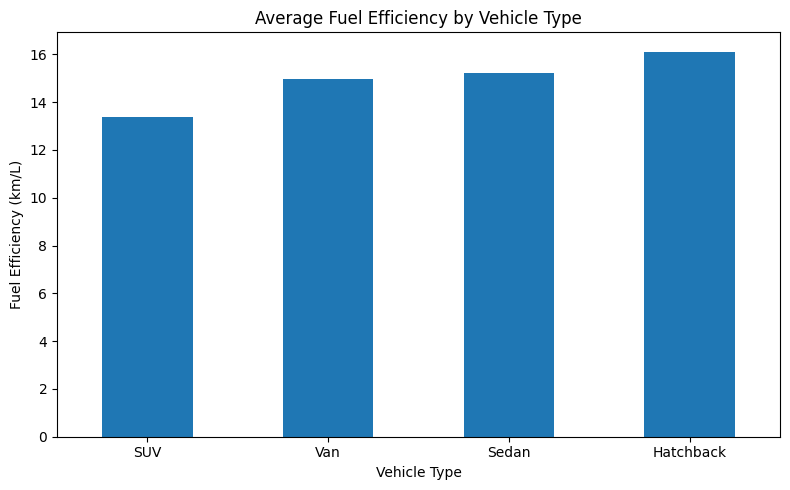

In [ ]:
# Bar plot: mean fuel efficiency by vehicle type
mean_efficiency = df_clean.groupby("Vehicle_Type")["Fuel_Efficiency_km_per_L"].mean().sort_values()

plt.figure(figsize=(8, 5))
mean_efficiency.plot(kind="bar")
plt.title("Average Fuel Efficiency by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Fuel Efficiency (km/L)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

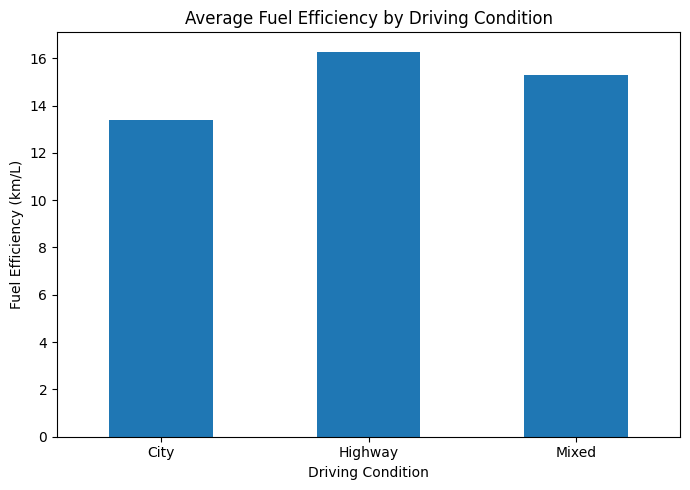

In [ ]:
# Bar plot: mean fuel efficiency by driving condition
condition_efficiency = df_clean.groupby("Driving_Condition")["Fuel_Efficiency_km_per_L"].mean()

plt.figure(figsize=(7, 5))
condition_efficiency.plot(kind="bar")
plt.title("Average Fuel Efficiency by Driving Condition")
plt.xlabel("Driving Condition")
plt.ylabel("Fuel Efficiency (km/L)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

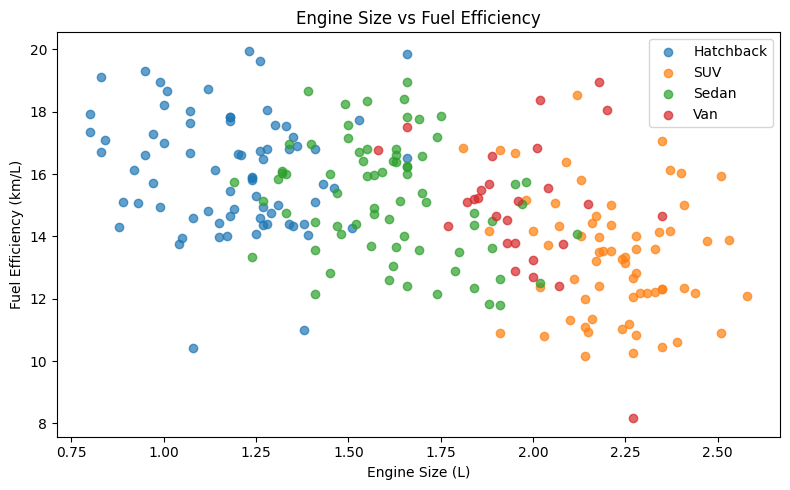

In [ ]:
# Scatter plot: engine size versus fuel efficiency
plt.figure(figsize=(8, 5))
for vehicle in sorted(df_clean["Vehicle_Type"].unique()):
    subset = df_clean[df_clean["Vehicle_Type"] == vehicle]
    plt.scatter(subset["Engine_Size_L"], subset["Fuel_Efficiency_km_per_L"], label=vehicle, alpha=0.7)
plt.title("Engine Size vs Fuel Efficiency")
plt.xlabel("Engine Size (L)")
plt.ylabel("Fuel Efficiency (km/L)")
plt.legend()
plt.tight_layout()
plt.show()

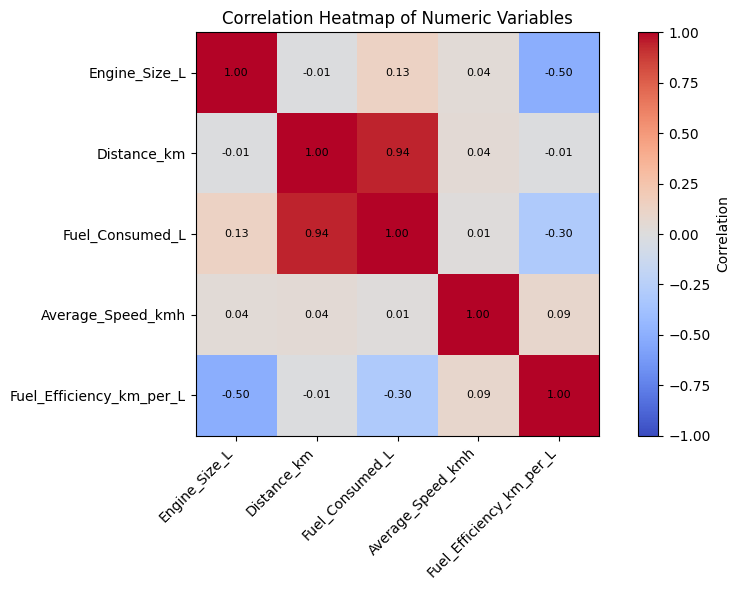

In [ ]:
# Correlation heatmap using Matplotlib (no additional plotting library required).
numeric_data = df_clean.select_dtypes(include="number")
corr = numeric_data.corr()

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
ax.set_title("Correlation Heatmap of Numeric Variables")
fig.colorbar(im, ax=ax, label="Correlation")
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Conclusion:** The bar charts compare average efficiency by category, the scatter plot helps inspect the association between engine size and efficiency, and the heatmap shows pairwise linear correlations. Correlation alone does not prove causation.

## Additional Analysis: Estimate Fuel Needed for a Trip
**Concept:** Estimate fuel required from distance and average efficiency using:

\[
\text{Fuel required (L)} = \frac{\text{Distance (km)}}{\text{Fuel efficiency (km/L)}}
\]

In [ ]:
trip_distance_km = 350
assumed_efficiency_km_per_l = df_clean["Fuel_Efficiency_km_per_L"].median()
estimated_fuel_l = trip_distance_km / assumed_efficiency_km_per_l

print(f"Trip distance: {trip_distance_km} km")
print(f"Assumed efficiency (dataset median): {assumed_efficiency_km_per_l:.2f} km/L")
print(f"Estimated fuel required: {estimated_fuel_l:.2f} L")

Trip distance: 350 km
Assumed efficiency (dataset median): 14.97 km/L
Estimated fuel required: 23.38 L


## Overall Conclusion
This project demonstrates a complete exploratory data analysis workflow for vehicle fuel consumption:

1. Prepared and inspected the dataset.
2. Used NumPy to calculate summary statistics.
3. Used Pandas grouping and aggregation to compare vehicle types and driving conditions.
4. Handled missing values and checked potential anomalies.
5. Created bar charts, a scatter plot, and a correlation heatmap.
6. Estimated fuel required for a trip using fuel efficiency.

